# Customer Churn Analysis & Exploration

## Internship Project: CodeNova AI/ML Batch 02

### Objective
The objective of this project is to perform Exploratory Data Analysis (EDA) on a telecom customer churn dataset to identify the factors that influence customers to leave a company.

### Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

### Project Scope
1. Dataset loading and exploration.
2. Statistical profiling.
3. Missing value detection.
4. Customer tenure analysis.
5. Monthly charges analysis.
6. Contract-wise churn analysis.
7. Data visualization.
8. Business insights and conclusions.

In [2]:
# Check missing values in the dataset

print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:


NameError: name 'df' is not defined

In [ ]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")



In [4]:
# Load the dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")


NameError: name 'pd' is not defined

In [5]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (7043, 21)


In [6]:
# Check missing values

print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [7]:
# Replace blank spaces with NaN

df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)

# Convert TotalCharges into numeric format

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Missing values converted successfully!")

Missing values converted successfully!


In [8]:
# Check missing values after conversion

print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [9]:
# Fill missing values using median

median_value = df['TotalCharges'].median()

df['TotalCharges'] = df['TotalCharges'].fillna(median_value)

print("Missing values handled successfully!")

# Verify again

print("\nRemaining Missing Values:")
print(df.isnull().sum().sum())

Missing values handled successfully!

Remaining Missing Values:
0


In [10]:
# Statistical summary of numerical columns

df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928
std,0.368612,24.559481,30.090047,2265.270398
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,402.225000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


### Categorical Statistical Analysis: Observations

1. The dataset contains 7,043 customer records.
2. The gender distribution is nearly balanced between male and female customers.
3. Fiber optic is the most frequently used internet service.
4. Month-to-month is the most common contract type.
5. Electronic check is the most frequently used payment method.
6. Most customers have not discontinued the company's services.
   
These observations provide an initial understanding of customer characteristics and service preferences.

In [13]:
# Count customers in each churn category

print("Customer Churn Count:")
print(df['Churn'].value_counts())

Customer Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


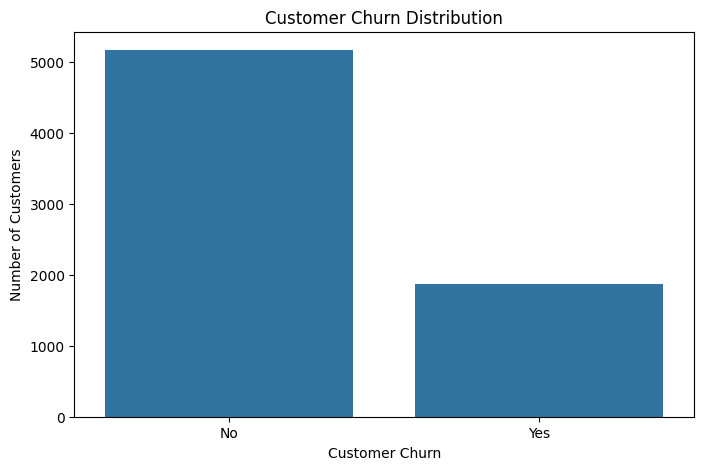

In [14]:
# Customer Churn Distribution

plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.savefig('customer_churn_distribution.png',
            dpi=300, bbox_inches='tight')

plt.show()

### Business Insight: Customer Churn Distribution

The analysis shows that approximately 73.46% of customers stayed with the company, while 26.54% discontinued its services.

This indicates that although most customers are retained, the company still loses approximately one-fourth of its customers.

The company should investigate the reasons behind customer churn and develop better customer retention strategies.

In [16]:
# Contract-wise customer churn count

contract_churn = pd.crosstab(df['Contract'], df['Churn'])

print("Contract-wise Customer Churn:")
print(contract_churn)

Contract-wise Customer Churn:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [17]:
# Calculate churn percentage for each contract

contract_churn_percentage = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print("Contract-wise Churn Percentage:")
print(contract_churn_percentage.round(2))

Contract-wise Churn Percentage:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


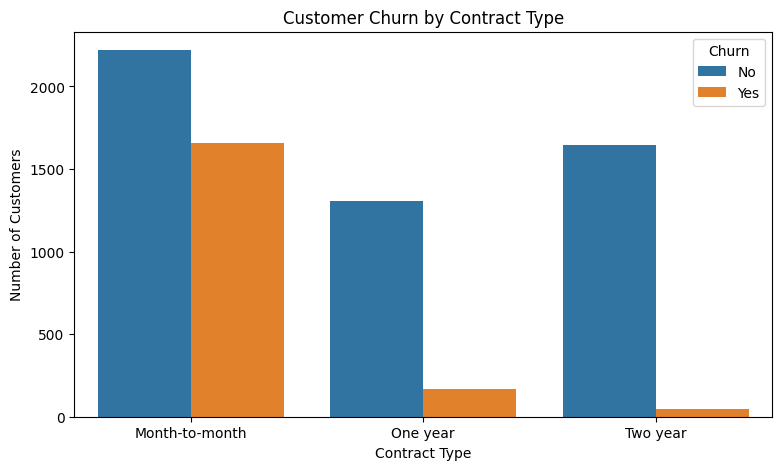

In [18]:
# Contract-wise Customer Churn Visualization

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.savefig(
    'contract_wise_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Business Insight: Contract-Wise Customer Churn

The contract-wise analysis helps identify the relationship between contract duration and customer churn.

It allows the company to understand which contract category experiences the highest customer loss.

Customers with shorter contract commitments may require additional retention strategies, loyalty benefits and attractive long-term contract offers.

In [19]:
# Calculate average tenure

print("Average Customer Tenure:",
      df['tenure'].mean().round(2), "months")

# Compare average tenure by churn status

print("\nAverage Tenure by Churn:")
print(df.groupby('Churn')['tenure'].mean().round(2))

Average Customer Tenure: 32.37 months

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


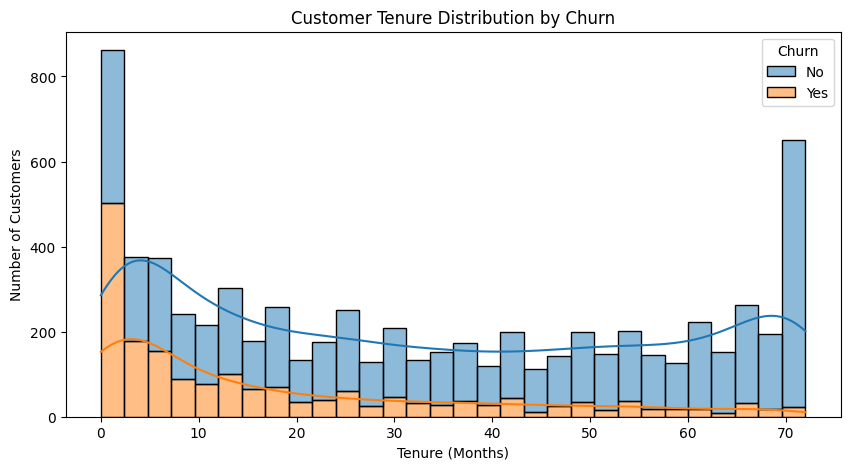

In [20]:
# Customer Tenure Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    kde=True,
    multiple='stack'
)

plt.title('Customer Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.savefig(
    'customer_tenure_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

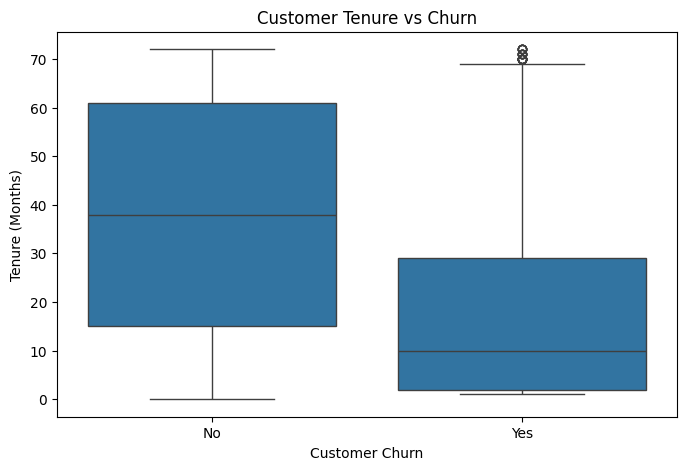

In [21]:
# Tenure vs Churn Box Plot

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='tenure'
)

plt.title('Customer Tenure vs Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Tenure (Months)')

plt.savefig(
    'tenure_vs_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Business Insight: Customer Tenure Analysis

Customer tenure analysis helps understand the relationship between the duration of customer relationships and customer churn.

By comparing the tenure of customers who stayed with the company and those who left, we can identify whether newer or long-term customers are more likely to discontinue services.

The company can use these findings to improve customer retention strategies, especially for customers who are at a higher risk of leaving.done


In [22]:
# Calculate average monthly charges

print("Overall Average Monthly Charges:",
      df['MonthlyCharges'].mean().round(2))

# Compare monthly charges by churn status

print("\nAverage Monthly Charges by Churn:")

print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

Overall Average Monthly Charges: 64.76

Average Monthly Charges by Churn:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


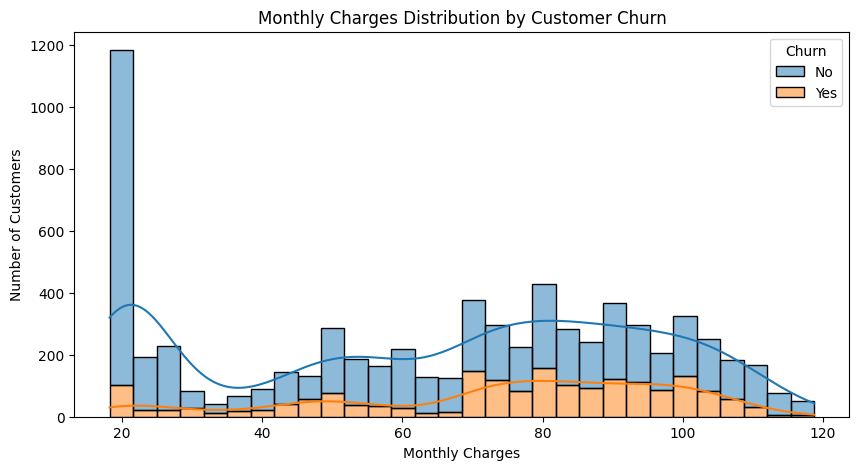

In [23]:
# Monthly Charges Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='MonthlyCharges',
    hue='Churn',
    bins=30,
    kde=True,
    multiple='stack'
)

plt.title('Monthly Charges Distribution by Customer Churn')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.savefig(
    'monthly_charges_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

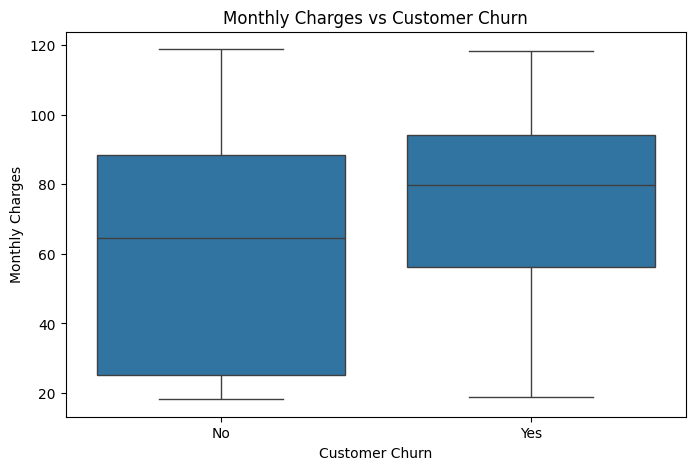

In [24]:
# Monthly Charges vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Monthly Charges')

plt.savefig(
    'monthly_charges_vs_churn.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Business Insight: Monthly Charges Analysis

Monthly charges analysis helps identify whether the amount customers pay influences their decision to continue or discontinue services.

By comparing the average monthly charges of customers who stayed and those who left, we can understand the relationship between pricing and customer churn.

The company can use these findings to review its pricing plans and provide suitable offers to customers who may be at risk of leaving.

In [25]:
# Select numerical columns

numerical_df = df.select_dtypes(include=np.number)

# Calculate correlation

correlation_matrix = numerical_df.corr()

print(correlation_matrix)

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016567        0.220173      0.102652
tenure               0.016567  1.000000        0.247900      0.825464
MonthlyCharges       0.220173  0.247900        1.000000      0.650864
TotalCharges         0.102652  0.825464        0.650864      1.000000


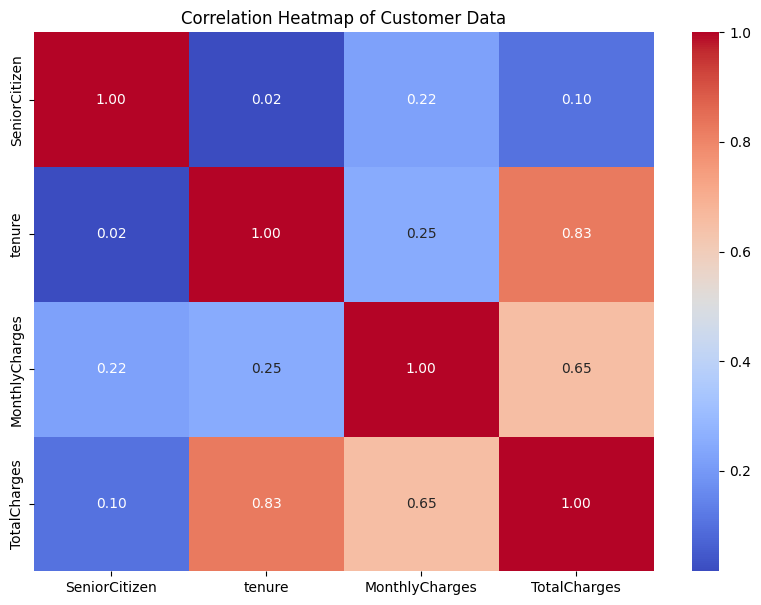

In [26]:
# Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Customer Data')

plt.savefig(
    'correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Business Insight: Correlation Analysis

Correlation analysis helps identify relationships between numerical customer attributes.

It helps understand how customer tenure, monthly charges and total charges are related to each other.

These relationships provide useful information for understanding customer behaviour and supporting better business decisions.

In [27]:
# Final Customer Churn Analysis Summary

print("========== CUSTOMER CHURN ANALYSIS ==========")

# Total customers
print("\nTotal Customers:", len(df))

# Churn count
print("\nCustomer Churn Count:")
print(df['Churn'].value_counts())

# Churn percentage
print("\nChurn Percentage:")
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

# Average tenure
print("\nAverage Tenure by Churn:")
print(df.groupby('Churn')['tenure'].mean().round(2))

# Average monthly charges
print("\nAverage Monthly Charges by Churn:")
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

# Contract-wise churn
print("\nContract-wise Churn:")
print(pd.crosstab(df['Contract'], df['Churn']))

# Contract-wise churn percentage
print("\nContract-wise Churn Percentage:")
print((pd.crosstab(df['Contract'], df['Churn'],
                  normalize='index') * 100).round(2))

print("\n========== ANALYSIS COMPLETED ==========")

========== CUSTOMER CHURN ANALYSIS ==========

Total Customers: 7043

Customer Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average Monthly Charges by Churn:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

Contract-wise Churn:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Contract-wise Churn Percentage:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

========== ANALYSIS COMPLETED ==========


In [28]:
# Create a folder for project visualizations

import os
import shutil

os.makedirs("Customer_Churn_Visualizations", exist_ok=True)

# List of generated graphs
files = [
    'customer_churn_distribution.png',
    'contract_wise_churn.png',
    'customer_tenure_distribution.png',
    'tenure_vs_churn.png',
    'monthly_charges_distribution.png',
    'monthly_charges_vs_churn.png',
    'correlation_heatmap.png'
]

# Copy graphs into the folder

for file in files:
    if os.path.exists(file):
        shutil.copy(file, "Customer_Churn_Visualizations")
        print(file, "Exported successfully")
    else:
        print(file, "Not found")

customer_churn_distribution.png Exported successfully
contract_wise_churn.png Exported successfully
customer_tenure_distribution.png Exported successfully
tenure_vs_churn.png Exported successfully
monthly_charges_distribution.png Exported successfully
monthly_charges_vs_churn.png Exported successfully
correlation_heatmap.png Exported successfully


In [29]:
import shutil
from google.colab import files

shutil.make_archive(
    'Customer_Churn_Visualizations',
    'zip',
    'Customer_Churn_Visualizations'
)

files.download('Customer_Churn_Visualizations.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# Calculate churn percentage

churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print("Customer Churn Percentage:")
print(churn_percentage.round(2))

Customer Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [11]:
# Statistical summary of categorical columns

df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


In [12]:
# Check duplicate records

print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


In [ ]:
df.head()

In [ ]:

# Check dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()
